# II. Preparación y Análisis de Datos
# Capítulo 5 - Exploración de Datos con Descripción Estadística (Ejercicios)

<div style="border-top: 20px solid #b6effb; border-bottom: 20px solid #b6effb; background-color: #cff4fc; color: #055160">

En estos ejercicios se busca aplicar los conocimientos adquiridos de programación en **Python** para profundizar en tres conceptos de estadística extremadamente útiles para el **EDA** y posteriormente, para el desarrollo de modelos predictivos: 

* La **Ley de los grandes números** que nos ayudará a entender mejor por qué se buscan contar con la mayor cantidad de datos posibles cuando hacemos análisis estadístico. 

* El **Teorema del límite central** que nos muestra cómo la distribución normal surge de forma natural en las aplicaciones y cálculos vinculados a la ciencia de datos.

* El **Teorema de Bayes** que fundamenta la lógica asociada a la importancia de nueva información y cómo este criterio puede ayudarnos a pronosticar eventos futuros.

</div>

## Ley de los grandes números

La Ley de los grandes números, establecida empíricamente por Cardano (1550) y demostrada formalmente por Jakob Bernoulli (1713), especifica que el estadístico $\bar\theta$ de una muestra de tamaño $n$ extraída de una población cualquiera, convergerá hacia el estadístico poblacional $\theta$ a medida que $n$ aumenta. En términos matemáticos si recuerdas algo de límites esta definición sería así:

$$ \lim_{n\rightarrow \infty} \bar\theta = \theta $$

Consideremos por ejemplo al estadístico **media**, lo que nos dice esta ley es que el promedio de una parte (muestra) de un conjunto de datos (población), será similar al promedio de todo el conjunto siempre que esa parte sea suficientemente grande.

Vamos a probar esto con nuestros conocimientos de **Python**.

### Ejercicio 1

Importa las librerías **random**, **numpy**, **pandas** y **matplotlib**. 

In [1]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Genera una lista con 2,000 valores aleatorios que sigan una distribución lognormal replicando el siguiente código:

```py
rng = np.random.default_rng()
poblacion = [rng.lognormal() for i in range(2000)]
```

Esta colección de valores será nuestra población.

In [2]:
rng = np.random.default_rng()
poblacion = [rng.lognormal() for i in range(2000)]

Calcula la media de esta población y guarda el resultado en la variable `prom_poblacion`.

In [3]:
prom_poblacion = np.mean(poblacion)
print(f"Media de la población: {prom_poblacion:.3f}")

Media de la población: 1.596


Extrae una muestra aleatoria de tamaño 5 de tu población utilizando la función `sample` de la librería **random**. Guarda tu resultado en la variable `muestra`.

In [4]:
muestra = random.sample(poblacion, 5)
print(muestra)

[0.5982773251586612, 5.008382662973326, 2.2877522316695433, 0.3618355062301009, 1.9242473989740183]


Calcula el promedio de esta muestra y guárdala en una variable `prom_muestra`.

In [5]:
prom_muestra = np.mean(muestra)
print(f"Media de la muestra: {prom_muestra:.3f}")

Media de la muestra: 2.036


Es posible que el promedio de la muestra obtenido no sea tan parecido al de la población. No te preocupes, usaremos la lógica de la ley de los grandes números para mejorar esta aproximación.

### Ejercicio 2

Crea una lista `prom_lista` que contenga cálculos del promedio de muestras de forma equivalente al realizado en el ejercicio anterior. Solamente que ahora considera como tamaño de las muestras valores que inicien en 5 y terminen en 1,900, con saltos de 5 unidades (es decir, 5, 10, 15, 20, 25, ..., 995, 1000, ..., 1895, 1900). 

In [6]:
prom_lista = []
for n in range(5,1905,5):
    muestra = random.sample(poblacion, n)
    prom_lista.append(np.mean(muestra))

Crea un dataframe que contenga dos columnas:

* La primera debe especificar los tamaños de muestra que utilizaste en el código anterior.

* La segunda debe especificar los valores guardados en tu lista de promedios.

In [7]:
df_promedios = pd.DataFrame(dict(
    n = range(5,1905,5),
    promedio = prom_lista
))
df_promedios.sample(10)

,n,promedio
363,1820,1.609723
231,1160,1.558813
314,1575,1.618500
338,1695,1.587411
316,1585,1.597205
254,1275,1.566473
116,585,1.637590
82,415,1.665024
371,1860,1.605327
40,205,1.762429


Grafica de forma simple la evolución de los promedios obtenidos a medida que se incrementa el tamaño de la muestra. Incluye una linea horizontal en color rojo que muestre el promedio de la población.

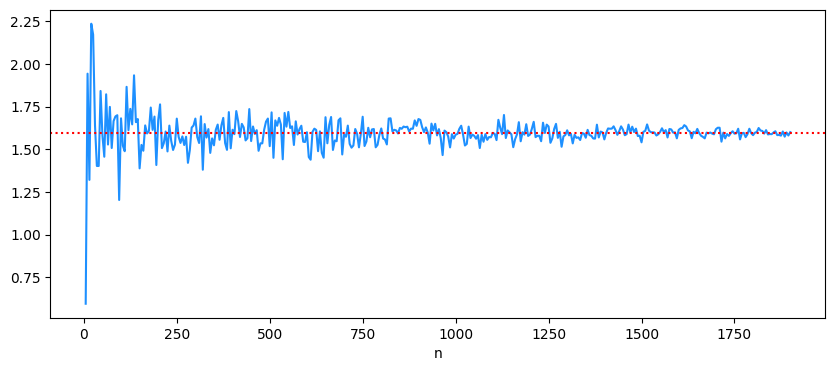

In [8]:
df_promedios.plot(
    x = "n",
    y = "promedio",
    legend = None,
    figsize = [10,4],
    color = "dodgerblue"
)
plt.axhline(y = prom_poblacion, color = "red", linestyle = ":")
plt.show()

Si todo fue hecho correctamente hasta ahora, deberías evidenciar que el promedio de las muestras converge hacia el promedio de la población a medida que el tamaño de muestra aumenta. Justamente lo que indica la ley de los grandes números.

### Ejercicio 3

Intenta comprobar que esta ley igualmente se cumple para otros estadísticos como la desviación estándar. Puedes utilizar la función `np.std` para asistirte en tus cálculos.

In [9]:
# Calcular std de la poblacion
desv_poblacion = np.std(poblacion)
print(f"Desviacion de la poblacion: {desv_poblacion:.3f}")

Desviacion de la poblacion: 2.014


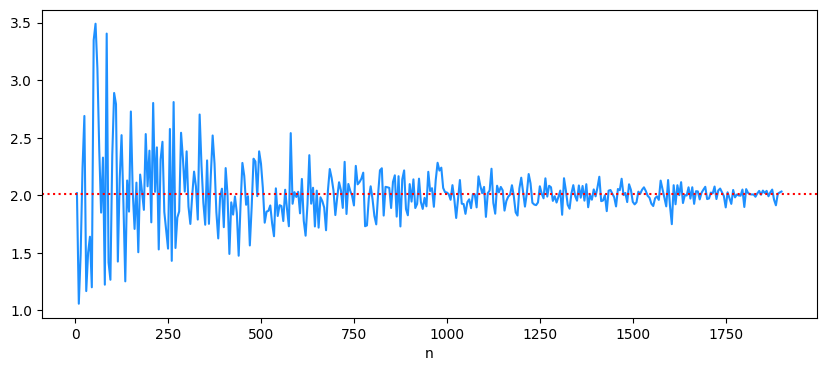

In [ ]:
# Calcular std para distintos tamaños de muestra
desv_lista = []
for n in range(5,1905,5):
    muestra = random.sample(poblacion, n)
    desv_lista.append(np.std(muestra))

# Crear dataframe con desviaciones muestrales
df_desviaciones = pd.DataFrame(dict(
    n = range(5,1905,5),
    std = desv_lista
))

# Graficar evolución de desviaciones
df_desviaciones.plot(
    x = "n",
    y = "std",
    legend = None,
    figsize = [10,4],
    color = "dodgerblue"
)
plt.axhline(y = desv_poblacion, color = "red", linestyle = ":")
plt.show()

Como puedes observar, la ley de los grandes números es una de las muchas razones por las cuales a los analistas y científicos de datos nos gustan las tablas "grandes" en lo que respecta a cantidad de observaciones. Mientras más datos, se pueden obtener estimaciones más adecuadas y representativas de la realidad.

<div class="alert alert-info">

La Ley de los grandes números funciona siempre y cuando el estadístico muestral que utilicemos sea *insesgado*. Un estimado es insesgado si su valor esperado es igual a aquel de la variable, esto es:

$$ \mathbb E\left(\,\bar\theta\, \right) = \mathbb E(X)$$

donde $X$ representa la variable en cuestión. 

A continuación podrás ver la demostración que justamente confirma que la media aritmética es un estimador insesgado:

$$ \mathbb E\left(\,\bar X \, \right) = \mathbb E\left(\,\frac{\sum_{i=1}^{n} x_i}{n} \, \right)$$
$$ = \frac{1}{n}\mathbb E\left(\,\sum_{i=1}^{n} x_i\, \right) = \frac{1}{n} \sum_{i=1}^{n} \mathbb E\left(x_i\right) $$
$$ = \frac{1}{n} \sum_{i=1}^{n} \mathbb E(X) = \frac{n}{n} \mathbb E(X) = \mathbb E(X)  $$

Te sugiero que la investigues a detalle para que comprendas cómo se operan con valores esperados.

</div>

## Teorema del límite central

El Teorema del límite central se constituye en una herramienta fundamental de todo análisis basado en estadística, pues especifica que la distribución del promedio de una muestra aleatoria extraída de una población, tenderá a ser *Normal* a medida que el tamaño de muestra $n$ se incrementa. Además esta distribución tendrá los siguientes parámetros:

* Centralidad en la media de la población.

* Error estándar $s = \sigma/\sqrt{n}$, donde $\sigma$ corresponde a la desviación estándar poblacional.

En términos más simples aunque no tan precisos, este teorema nos dice que el promedio de cualquier variable sigue una distribución en forma de campana si se cuenta con la suficiente cantidad de observaciones.

El teorema fue planteado ya en 1733 por de Moivre, con las primeras formalizaciones a principios del siglo XIX gracias a las investigaciones de Laplace y Gauss. Su demostración más moderna y formal llegaría un siglo más tarde gracias al trabajo de Lyapunov. Vamos ahora a verificarlo con nuestros conocimientos de **Python**.

### Ejercicio 1

Simula el lanzamiento de un dado común utilizando la función `randint` de la librería **random**. Por si necesitas saberlo un dado común es aquel que tiene 6 caras y que al lanzarlo cada cara tiene igual probabilidad de salir, esto es, una entre seis posibilidades.

In [11]:
random.randint(1,6)

3

Imagina ahora que lanzas el dado 50 veces. Guarda los resultados obtenidos en una lista llamada `lanzamientos`. 

In [12]:
lanzamientos = [random.randint(1,6) for i in range(50)]
print(lanzamientos)

[1, 6, 3, 1, 5, 4, 1, 1, 3, 5, 4, 2, 1, 3, 2, 4, 6, 1, 6, 2, 5, 6, 6, 6, 6, 4, 1, 3, 6, 1, 3, 6, 4, 1, 4, 1, 3, 3, 3, 1, 6, 6, 3, 5, 5, 1, 6, 4, 4, 1]


Calcula el promedio de tus lanzamientos y guarda el resultado en la variable `prom_lanzamientos`.

In [ ]:
prom_lanzamientos = np.mean(lanzamientos)
print(f"Promedio de lanzamientos de dado: {prom_lanzamientos}")

Promedio de lanzamientso de dado: 3.5


Si has hecho todo bien hasta ahora, el promedio obtenido debería ser un valor cercano a $3.5$. ¿Podrías intuir por qué este valor?

### Ejercicio 2

Repite 10 veces este experimento de lanzar 50 dados. Guarda el promedio de cada una de estas iteraciones en una variable llamada `promedios`. 

**NOTA:** Vale señalar que para efectos de asimilar lo solicitado con la definición del Teorema del límite central, nuestro tamaño de muestra $n$ sería 10.  

In [14]:
promedios = []
for i in range(10):
    lanzamientos = [random.randint(1,6) for i in range(50)]
    prom_lanzamientos = float(np.mean(lanzamientos))
    promedios.append(prom_lanzamientos)

print(promedios)

[3.66, 3.26, 3.62, 3.66, 3.54, 3.6, 3.54, 3.98, 3.38, 3.5]


Grafica estos resultados en un histograma simple que tenga aproximadamente $\sqrt{n}$ barras. Recuerda que en este caso $n$ sería 10. 

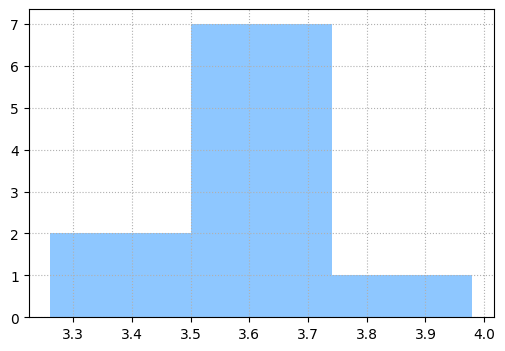

In [15]:
plt.figure(figsize = [6,4])
plt.hist(
    promedios, 
    bins = int(np.sqrt(10)), 
    color = "dodgerblue", 
    alpha = 0.5
)
plt.grid(linestyle = ":")
plt.show()

El gráfico no parece sugerir que este promedio siga una distribución *Normal*. No te preocupes, vamos a llegar a ello con el Teorema del límite central.

### Ejercicio 3

Define la función `tlc` que automatice el proceso del ejercicio anterior, tomando como entrada un valor de lanzamientos $n$ y devolviendo un histograma con aproximadamente $\sqrt{n}$ barras. 

In [16]:
def tlc (n):
    
    # Iterar n veces
    promedios = []
    for i in range(n):
        lanzamientos = [random.randint(1,6) for i in range(50)]
        prom_lanzamientos = np.mean(lanzamientos)
        promedios.append(prom_lanzamientos)
    
    # Histograma de las iteraciones
    plt.figure(figsize = [6,4])
    plt.hist(
        promedios, 
        bins = int(np.sqrt(n)), 
        color = "dodgerblue", 
        alpha = 0.5
    )
    plt.grid(linestyle = ":")
    plt.show()

Utiliza tu función `tlc` para ver la distribución resultante en un tamaño de muestra $n$ de 100.

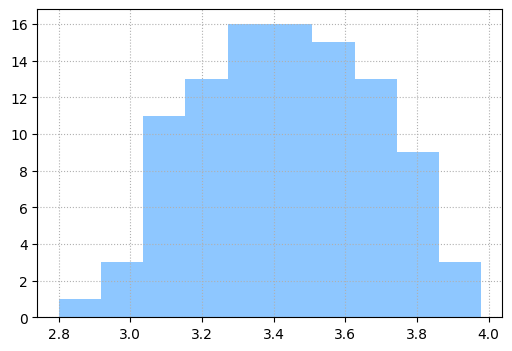

In [17]:
tlc(100)

Repite el ejercicio con tamaños de muestra de 1,000 y 10,000.

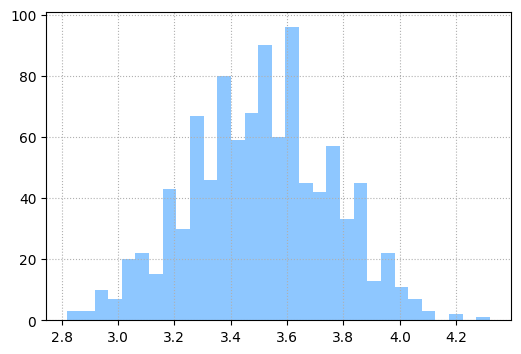

In [18]:
# Histograma con 1,000 experimentos
tlc(1000)

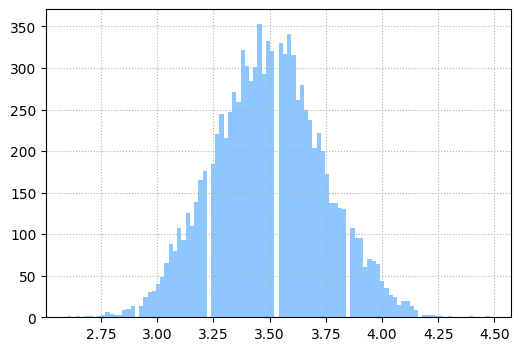

In [19]:
# histograma con 10,000 experimentos
tlc(10000)

Si todo se ha hecho correctamente, notarás que los últimos histogramas tienen una forma muy familiar: la de una distribución *Normal*. Justamente aquella predicha por el Teorema del límite central.

<div class="alert alert-info">

Seguramente te preguntarás cuál es la utilidad de este resultado en tu aprendizaje de ciencia de datos. Aquí algunas respuestas:

* En inferencia estadística que verás en el siguiente capítulo, la existencia y decisión de uso de algunas pruebas de hipótesis (como las asociadas a medias), dependen exclusivamente de que se cumpla esta proposición. Es por este motivo que cuando el tamaño de muestra es pequeño, se sugiere el uso del test U de Mann-Whitney; no así cuando el tamaño de muestra es grande donde se recomiendan las pruebas t que asumen que las medias siguen una distribución simétrica en forma de campana tal y como hace referencia este teorema. 

* La confiabilidad y robustez de muchos algoritmos que se utilizan en el modelamiento predictivo y aprendizaje computacional necesitan que las variables a predecir sigan una distribución normal. Por tanto, la agregación a valores promedio puede garantizar el cumplimiento de este requerimiento en específico.

* Pero ante todo, la distribución normal es bastante conocida y documentada, por lo que mantener variables que sigan esta distribución facilita su estudio y comprensión. No sucedería lo mismo si el comportamiento observado tuviera propiedades menos "naturales" que exigirían mayor complejidad en nuestros análisis.

</div>

## Teorema de Bayes



La existencia de información adicional se constituye en un factor determinante para la actualización de nuestras creencias previas respecto a un evento en particular. Por tanto, el contar con nueva evidencia sobre el cumplimiento de un suceso se traduce en tomar decisiones específicas basadas en nuestra observación y una adaptación más adecuada al entorno en que nos estamos desenvolviendo.

Esta proposición lógica tiene su representación dentro de la teoría de probabilidades a través del **Teorema de Bayes**. El mismo afirma que dados dos eventos $A$ y $B$ cualesquiera, se cumple que

$$ P(A \mid B) = \frac{P(B \mid A) P(A)}{P(B)} $$

donde $P(A)$ es la probabilidad previa que conocemos del evento $A$, y $P(A \mid B)$ es la probabilidad posterior o ajustada dada la observación del suceso $B$.

Veamos cómo podemos aplicar esta idea tan simple para construir un modelo de pronóstico de *spam* en correos electrónicos.

### Ejercicio 1

De un artículo publicado en un recorte de prensa se conoce que el 28.5% de los correos electrónicos que recibe una persona cualquiera son *spam*. Allí también se indica que una característica distintiva de esos mensajes maliciosos es que en su contenido aparece mucho la palabra "Gratis"; de hecho el 82.2% de ellos lo tiene.

Por otra parte, revisando una muestra de 45 correos recibidos que NO son *spam*, tú has podido evidenciar que 5 presentan dicho término en su contenido.

Definamos por tanto al evento $A$ como el que un correo sea *Spam*, y a $B$ como que aparezca la palabra "Gratis". Guarda las probabilidades descritas aquí en las variables `p_s`, `p_g_s` y `p_g_nos` respectivamente.

In [20]:
p_s = 0.285
p_g_s = 0.822
p_g_nos = 5/45

print(f"P(Spam): {p_s:.1%}")
print(f"P(Gratis | Spam): {p_g_s:.1%}")
print(f"P(Gratis | No Spam): {p_g_nos:.1%}")

P(Spam): 28.5%
P(Gratis | Spam): 82.2%
P(Gratis | No Spam): 11.1%


Dados esto, calcula la probabilidad que un correo cualquiera contenga la palabra "Gratis". Considera para esto que 

$$ P(Gratis) = P(Gratis \mid Spam)P(Spam) + P(Gratis \mid No\_Spam)P(No\_Spam) $$

In [21]:
p_g = p_g_s * p_s + p_g_nos * (1 - p_s)
print(f"P(Gratis): {p_g:.1%}")

P(Gratis): 31.4%


Supongamos que recibimos un nuevo correo electrónico que en su contenido tiene la palabra "Gratis". Ante esta nueva evidencia, utiliza la definición del Teorema de Bayes para calcular la probabilidad que dicho correo sea *spam*. 

In [22]:
p_s_g = p_g_s * p_s / p_g
print(f"P(Spam | Gratis): {p_s_g:.1%}")

P(Spam | Gratis): 74.7%


### Ejercicio 2

Hasta ahora podemos estimar la probabilidad de que un nuevo mensaje recibido sea spam considerando solamente el hecho que contenga la palabra "Gratis". Intentemos agregar un nuevo atributo para fortalecer nuestro modelo predictivo.

Revisando nuevamente el artículo, notamos que además se destaca que el 54.3% de los correos maliciosos incorpora algún *link*. Por lo que decides contrastar esto con los 45 correos normales de nuestra muestra y detectas que apenas 2 de ellos presentan esta característica. 

Guarda estas nuevas probabilidad en las variables `p_l_s` y `p_l_nos`, respectivamente.

In [23]:
p_l_s = 0.543
p_l_nos = 2/45

print(f"P(Link | Spam): {p_l_s:.1%}")
print(f"P(Link | No Spam): {p_l_nos:.1%}")

P(Link | Spam): 54.3%
P(Link | No Spam): 4.4%


Calcula ahora la probabilidad que un correo cualquiera contenga un *link*.

In [24]:
p_l = p_l_s * p_s + p_l_nos * (1 - p_s)
print(f"P(Link): {p_l:.1%}")

P(Link): 18.7%


Suponiendo un nuevo correo que contiene un link, ¿cuál sería la probabilidad que el mismo sea *spam*?

In [25]:
p_s_l = p_l_s * p_s / p_l
print(f"P(Spam | Link): {p_s_l:.1%}")

P(Spam | Link): 83.0%


### Ejercicio 3

Es momento de combinar esta evidencia, calcula la probabilidad que un correo cualquiera tenga un link y la palabra "Gratis". Para ello, puedes asumir que estos dos eventos son condicionalmente independientes dado el tipo de correo tal que

$$ P(Gratis,\,Link \mid Spam) = P(Gratis \mid Spam) P(Link \mid Spam) $$

$$ P(Gratis,\,Link \mid No\_Spam) = P(Gratis \mid No\_Spam) P(Link \mid No\_Spam) $$

In [ ]:
p_gl = p_g_s * p_l_s * p_s + p_g_nos * p_l_nos * (1 - p_s)
print(f"P(Gratis, Link): {p_gl:.1%}")

P(Spam | Link): 13.1%


Utiliza este resultado para determinar qué tan probable es que un nuevo correo sea spam, dado que se observa que contiene un link y la palabra "Gratis".

In [27]:
p_s_gl = p_g_s * p_l_s * p_s / p_gl
print(f"P(Spam | Gratis, Link): {p_s_gl:.1%}")

P(Spam | Gratis, Link): 97.3%


¿Qué sucede ahora si el correo presenta solamente un link pero sin la palabra "Gratis"?

In [28]:
# Calcular probabilidad sin gratis y con link
p_nogl = (1 - p_g_s) * p_l_s * p_s + (1 - p_g_nos) * p_l_nos * (1 - p_s)

# Calcular probabilidad posterior de spam dada evidencia
p_s_nogl = (1 - p_g_s) * p_l_s * p_s / p_nogl
print(f"P(Spam | No Gratis, Link): {p_s_nogl:.1%}")

P(Spam | No Gratis, Link): 49.4%


Crea una visualización que evidencie las 4 posibles alternativas de evidencia y su correspondiente probabilidad posterior de que el correo sea *spam*.

In [29]:
# Calcular probabilidad posterior dado correo con gratis y sin link
p_gnol = p_g_s * (1 - p_l_s) * p_s + p_g_nos * (1 - p_l_nos) * (1 - p_s)
p_s_gnol = p_g_s * (1 - p_l_s) * p_s / p_gnol
print(f"P(Spam | Gratis, No Link): {p_s_gnol:.1%}")

P(Spam | Gratis, No Link): 58.5%


In [30]:
# Calcular probabilidad posterior dado correo sin gratis y sin link
p_nognol = (1 - p_g_s) * (1 - p_l_s) * p_s + (1 - p_g_nos) * (1 - p_l_nos) * (1 - p_s)
p_s_nognol = (1 - p_g_s) * (1 - p_l_s) * p_s / p_nognol
print(f"P(Spam | No Gratis, No Link): {p_s_nognol:.1%}")

P(Spam | No Gratis, No Link): 3.7%


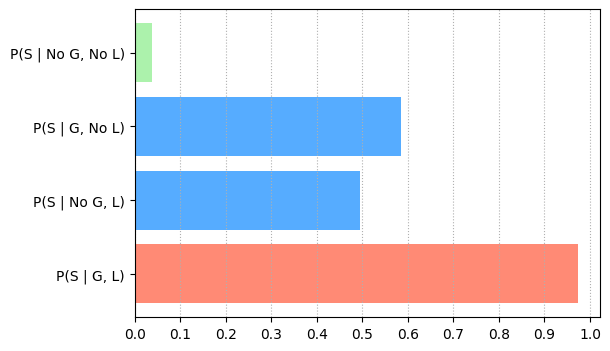

In [32]:
# Visualizar resultados de probabilidad posterior
plt.figure(figsize = [6,4])
plt.barh(
    y = ["P(S | G, L)", "P(S | No G, L)", "P(S | G, No L)", "P(S | No G, No L)"],
    width = [p_s_gl, p_s_nogl, p_s_gnol, p_s_nognol],
    color = ["tomato", "dodgerblue", "dodgerblue", "lightgreen"],
    alpha = 0.75
)
plt.xticks(ticks = np.array(range(0,11))/10)
plt.grid(axis = "x", linestyle = ":")
plt.show()

Gracias al Teorema de Bayes has logrado diseñar un modelo de pronóstico completo para organizar tu bandeja de entrada y evitar así nuevo contenido malicioso. Por ejemplo, podrías configurar tu cuenta para que siga estas instrucciones:

* Si en el contenido de cada correo entrante no aparecen la palabra "Gratis" ni links entonces se acepta y pasa a la bandeja de entrada.

* Si en el contenido aparecen ambas características se descarta automáticamente el mensaje por ser un *spam*.

* Si solamente hay alguna de las dos opciones se pasa a una carpeta de revisión.

<div class="alert alert-info">

En este ejercicio de hecho hemos construido una simplificación de un algoritmo de aprendizaje computacional conocido como **Clasificador Bayesiano**. En este algoritmo únicamente se adiciona un umbral de clasificación para identificar si un correo es o no spam. 

Por ejemplo, si se definiese este umbral en 0.5 para nuestro caso, entonces se concluiría que todos los correo que tengan la palabra "Gratis" serán maliciosos independiente de cualquier otra característica que presenten. Si en cambio el umbral se establece en 0.75, solamente se clasificarán así aquellos que presenten la palabra junto con un link.

</div>